# Check a spatial holdout

**AI & human decisions · 15–25 minutes · learning companion**

GeoLibre, RustGIS and GeoAI learning with browser-safe analyses and clearly separated native/model continuations.

**Learning question:** Can a rule fit one region and fail in another?

**Source project:** [JupyterLite-GeoLibre-GeoAI](https://github.com/jltobias/JupyterLite-GeoLibre-GeoAI).

This original index activity is **synthetic teaching analysis**. It uses invented values or authored metadata, no real people or sensitive locations, no remote APIs, and no AI model calls. It is a small companion to the source project, not a reproduction of that project's full course.

![Learning workflow](../../assets/empathy-iteration.svg)

Original atlas diagram, James L. Tobias and contributors, CC BY 4.0; see [asset provenance](../../visual-provenance.ipynb).


## Predict before running

Apply an authored linear rule to two invented spatial groups. Compare mean absolute errors to reveal a deliberate distribution shift. This is a fixed rule, not fitted model output.

Write a prediction and one assumption you would need to check. Run cells in order with **Shift+Enter**, or **Run → Run All Cells**. The next cell defines only local SVG display helpers; the following cell performs the analysis. Every graphic also prints its values as a text alternative.


In [1]:
from IPython.display import SVG, display
from html import escape

def svg(body, title, description, width=760, height=330):
    label = escape(title, quote=True)
    display(SVG(f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 {width} {height}" role="img" aria-label="{label}"><title>{escape(title)}</title><desc>{escape(description)}</desc><rect width="100%" height="100%" fill="#f5f5ef" rx="12"/>{body}</svg>'))

def bars(values, title, unit):
    print(title + ' | ' + unit + ':', {k:round(v,3) for k,v in values.items()})
    n = len(values)
    height = max(250, 82 + n*36)
    maximum = max(max(values.values()), 1)
    body = f'<text x="22" y="30" font-family="sans-serif" font-size="18" fill="#123c45">{escape(title)}</text>'
    for i,(key,value) in enumerate(values.items()):
        y=58+i*36
        body += f'<text x="22" y="{y+17}" font-family="sans-serif" font-size="13">{escape(str(key))}</text><rect x="205" y="{y}" width="{max(0,value)/maximum*440:.2f}" height="23" rx="3" fill="#16756b"/><text x="{213+max(0,value)/maximum*440:.2f}" y="{y+17}" font-family="sans-serif" font-size="13">{value:.2f}</text>'
    body += f'<text x="205" y="{height-15}" font-family="sans-serif" font-size="12">zero baseline · {escape(unit)}</text>'
    svg(body, title, 'Values are printed as a text alternative; consult the chart title for data status.', height=height)

def grid(values, columns, title):
    print(title + ':', [round(v,3) for v in values])
    maximum = max(max(values),1)
    size = 54
    body = f'<text x="22" y="30" font-family="sans-serif" font-size="18">{escape(title)}</text>'
    for i,v in enumerate(values):
        x=25+(i%columns)*size; y=52+(i//columns)*size
        light=92-50*v/maximum
        body += f'<rect x="{x}" y="{y}" width="50" height="50" fill="hsl(169,45%,{light:.1f}%)" stroke="#123c45"/><text x="{x+25}" y="{y+29}" text-anchor="middle" font-family="sans-serif" font-size="14" fill="#061c21">{v:.1f}</text>'
    svg(body,title,'Synthetic grid with values printed in each cell; no actual boundaries.',height=max(220,70+((len(values)+columns-1)//columns)*size))

def lines(series, title, xunit, yunit):
    print(title + ':', {k:[round(v,3) for v in vs] for k,vs in series.items()})
    maximum=max(max(vs) for vs in series.values()) or 1
    body=f'<text x="22" y="30" font-family="sans-serif" font-size="18">{escape(title)}</text><path d="M55 55V265H710" fill="none" stroke="#123c45"/>'
    for j,(name,vs) in enumerate(series.items()):
        color=['#16756b','#a34712','#41449c'][j%3]
        pts=' '.join(f'{55+i*650/max(1,len(vs)-1):.1f},{265-v*200/maximum:.1f}' for i,v in enumerate(vs))
        body+=f'<polyline points="{pts}" fill="none" stroke="{color}" stroke-width="3"/><text x="{60+j*220}" y="310" font-family="sans-serif" font-size="13" fill="{color}">{escape(name)}</text>'
    body+=f'<text x="55" y="288" font-family="sans-serif" font-size="12">{escape(xunit)} → · {escape(yunit)} ↑ · y starts at zero</text>'
    svg(body,title,'Synthetic series; printed values are the text alternative.')


Prediction rule: 2*x+1; all targets synthetic
Synthetic spatial holdout error | mean absolute error: {'near': 0.0, 'far': 7.0}


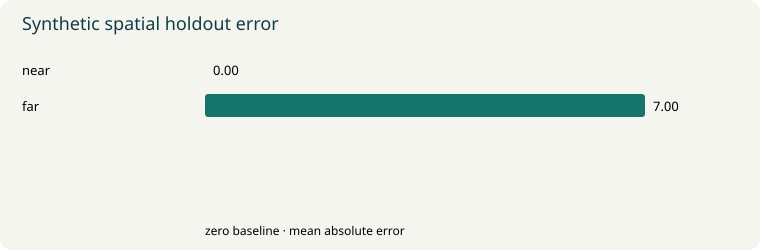

In [2]:
groups = {'near':[(1,3),(2,5),(3,7)], 'far':[(4,15),(5,18),(6,21)]}
errors = {g:sum(abs((2*x+1)-y) for x,y in pairs)/len(pairs) for g,pairs in groups.items()}
print('Prediction rule: 2*x+1; all targets synthetic')
bars(errors, 'Synthetic spatial holdout error', 'mean absolute error')


## Interpret the result

The rule is exact in the near group and biased in the far group. Random splitting could conceal this structured difference; low training error does not ensure geographic transfer.

Name the result, the assumption producing it, and one conclusion it cannot support. These are not clinical findings, causal effects or live model outputs.

## Change one thing

Create a third group and choose a holdout before changing the rule. Discuss data leakage and why evaluation units should match the deployment question.

Save a copy with **File → Save and Export Notebook As → Notebook** (or the file browser's Download command). Browser storage is local to this browser/profile; it is not a GitHub commit or shared database.


## Connect the idea

Compare this activity with another chapter on the same [learning path](../../index.ipynb). Keep the question, data status and interpretation visible when transferring a method.


## Sources, continuation and limits

**Source repository:** [JupyterLite-GeoLibre-GeoAI](https://github.com/jltobias/JupyterLite-GeoLibre-GeoAI).

**Source README:** [reviewed immutable version](https://github.com/jltobias/JupyterLite-GeoLibre-GeoAI/blob/777fa8965068b1e26b982162f17254ee2df7ec84/README.md); inspected 2026-11-01, commit `777fa8965068`. Repository content and linked works keep their original terms. Summaries and exercises here are newly authored.

Real GeoAI inference/native packages stay in supported local/server environments. Source's optional Ollama assistant needs separate installation and browser-origin permissions; use one tiny reviewed public fixture and a bounded request.

- [Read source Book](https://jltobias.github.io/JupyterLite-GeoLibre-GeoAI/) - Read the original project course and its own source notes. **HTTP 200 - entry only** (HTTP GET 2026-11-01; entry document only.)
- [Run source Lab](https://jltobias.github.io/JupyterLite-GeoLibre-GeoAI/lite/lab/index.html) - Run the source project notebooks; its dependencies and data terms apply. **HTTP 200 - entry only** (HTTP GET 2026-11-01; entry document only.)
- [Explore source 2D map](https://jltobias.github.io/JupyterLite-RustGIS/maps/2d.html) - Explore the original companion map and check its layer provenance. **HTTP 200 - entry only** (HTTP GET 2026-11-01; entry document only.)
- [Explore source 3D map](https://jltobias.github.io/JupyterLite-RustGIS/maps/3d.html) - Explore original extruded geography; height encodings require interpretation. **HTTP 200 - entry only** (HTTP GET 2026-11-01; entry document only.)
- [Explore source 3D scene](https://jltobias.github.io/JupyterLite-RustGIS/maps/scene.html) - Orbit the original conceptual scene; graphics support may be required. **HTTP 200 - entry only** (HTTP GET 2026-11-01; entry document only.)
- [Open source explorer](https://jltobias.github.io/JupyterLite-STAC-Browser/explorer/) - Use the original interactive discovery or teaching explorer. **HTTP 200 - entry only** (HTTP GET 2026-11-01; entry document only.)

**Runtime budget:** this default is fewer than 100 values and normally completes within seconds; allow 60 seconds per cell while first loading Python. For native/GPU tools, use the source's local/server guide in an isolated environment, start with one small public/synthetic fixture, limit a trial to 5 minutes, and inspect memory, provider costs and outputs before scaling. For live models, use an approved authenticated backend with server-side secrets and a bounded single request; do not put credentials or sensitive records into a browser. Nothing in this chapter calls those services.

[Central references](../../references.ipynb) · [Contribute](../../contributor-guide.ipynb)
